## 2D модель распределения кривых и оптимизации через градиентный спуск

**Information:** 
    *Это продвинутая версия программы, добавлен новый новый параметр оптимзации - высота. 
    

### 0. Настройки

In [3]:
# Настройка проекта
import matplotlib.pyplot as plt
import meep as mp
import conf
import torch
from lib import adjoint as mpa
from lib import torch_functions as tf
from lib import numpy_functions as nf
from lib import my_gui, my_decoders, my_sources
from lib import help_functions
from autograd import numpy as npa
import numpy as np
mp.verbosity(0) # decrease amount of output

# def J(FF):
#     # возможны две интерпретации 1. усреднение по волнам. 2. усреднение по точкам   
#     return npa.mean(npa.abs(FF[0, :, 2])**2/IPlane_base/max_per_column)
#     # Нормализованное сфокусированную интенсивность делим на нормализованную максимальную интенсивность Эйри.

def J(FF):
    """
    FF: массив формы (1, n_points, n_waves, …). 
    penalty_coef: коэффициент штрафа (подбирается эмпирически).
    """
    # вычисляем по‑точечную интенсивность: shape = (n_points, n_waves)
    I = npa.abs(FF[0, :, 2])**2 / IPlane_base / max_per_column

    # базовая цель — среднее по волнам
    J_base = npa.mean(I)
    
    # штраф за разброс между волнами (variance или std^2)
    penalty = penalty_coef * (npa.std(I))**2    # либо λ * (np.std(f_w))**2

    return J_base - penalty


""" Класс для одной длины волны """
"""
class OptFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, *x_tensors):
        # Сохранение форм и подготовка параметров дизайна
        rho_list = []
        shapes = []
        for x in x_tensors:
            arr = x.detach().cpu().numpy()
            if arr.shape[0] > 1:
                arr.squeeze()
            shapes.append(arr.shape)
            rho_list.append(arr.flatten())
        # вызов оптимизатора с numpy-массивами
        f0, grad_rho = opt(rho_list)
        ctx.grad_rho = grad_rho
        ctx.shapes = shapes
        ctx.device = x_tensors[0].device
        ctx.dtype = x_tensors[0].dtype

        # Правильное создание выходного тензора, чтобы связать grad_fn
        return torch.as_tensor(f0, device=ctx.device, dtype=ctx.dtype)

    @staticmethod
    def backward(ctx, grad_output):
        num_inputs = len(ctx.shapes)
        grads = []
        for idx, (g_np, shape) in enumerate(zip(ctx.grad_rho, ctx.shapes)):
            # ожидаем, что g_np — numpy-массив 1D
            g_arr = np.asarray(g_np, dtype=np.float64).reshape(shape)
            g_torch = torch.from_numpy(g_arr).to(device=ctx.device, dtype=ctx.dtype)
            grads.append(g_torch * grad_output)

        return tuple(grads)
        
        
Универсальный класс, надо проверить    
class OptFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, *x_tensors):

        # Forward pass for both single- and multi-frequency optimization.
        # Unwraps torch tensors to numpy arrays, calls external opt(), and saves gradients.

        rho_list = []
        shapes = []
        # Extract data and shapes
        for x in x_tensors:
            arr = x.detach().cpu().numpy()
            # if extra leading dim, squeeze it
            if arr.ndim > 1 and arr.shape[0] == 1:
                arr = arr.squeeze(0)
            shapes.append(arr.shape)
            rho_list.append(arr.flatten())

        # Call external optimizer: returns objective and gradients
        f0, grad_rho = opt(rho_list)

        # Save context for backward
        ctx.grad_rho = grad_rho
        ctx.shapes = shapes
        ctx.device = x_tensors[0].device
        ctx.dtype = x_tensors[0].dtype

        # Return scalar objective as torch tensor
        return torch.as_tensor(f0, device=ctx.device, dtype=ctx.dtype)

    @staticmethod
    def backward(ctx, grad_output):

        # Backward pass: reshape and convert numpy gradients to torch,
        # handling both single- and multi-frequency cases.

        grads = []
        for g_np, shape in zip(ctx.grad_rho, ctx.shapes):
            # For multi-frequency, collapse along freq axis
            if g_np.ndim == 2:
                # average gradients over frequencies
                g_arr = np.mean(g_np, axis=1).reshape(shape)
            else:
                # single-frequency gradient
                g_arr = np.asarray(g_np, dtype=np.float64).reshape(shape)

            # Convert to torch tensor and scale by upstream grad_output
            g_torch = torch.from_numpy(g_arr).to(device=ctx.device, dtype=ctx.dtype)
            grads.append(g_torch * grad_output)

        # Return gradient for each input
        return tuple(grads)

# Convenience wrapper

def opt_torch(*x_tensors):

    # Apply the OptFunction in a torch-friendly way.

    return OptFunction.apply(*x_tensors)


"""

""" Класс для n длин волн """
class OptFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, *x_tensors):
        # Сохранение форм и подготовка параметров дизайна
        rho_list = []
        shapes = []
        for x in x_tensors:
            arr = x.detach().cpu().numpy()
            if arr.shape[0] > 1:
                arr.squeeze()
            shapes.append(arr.shape)
            rho_list.append(arr.flatten())
        # вызов оптимизатора с numpy-массивами
        f0, grad_rho = opt(rho_list)
        # print(f"grad_rho len is {len(grad_rho)}")
        # print(f"grad_rho shape is {grad_rho[0].shape}")
        ctx.grad_rho = grad_rho
        ctx.shapes = shapes
        ctx.device = x_tensors[0].device
        ctx.dtype = x_tensors[0].dtype

        # Правильное создание выходного тензора, чтобы связать grad_fn
        return torch.as_tensor(f0, device=ctx.device, dtype=ctx.dtype)

    @staticmethod
    def backward(ctx, grad_output):
        grads = []
        for idx, (g_np, shape) in enumerate(zip(ctx.grad_rho, ctx.shapes)):
            # g_np: numpy‑массив формы (N, nfreq)
            # 1) коллапсируем в вектор длины N
            g_collapsed = np.mean(g_np, axis=1)       # <–– усредняем по волнам
            # 2) возвращаем исходную форму тензора
            g_arr = g_collapsed.reshape(shape)

            g_torch = torch.from_numpy(g_arr).to(device=ctx.device, dtype=ctx.dtype)
            grads.append(g_torch * grad_output)

        # Если есть лишние или недостающие, они будут видны по логам
        return tuple(grads)
def opt_torch(*x_tensors):
    return OptFunction.apply(*x_tensors)

## Основная программа
### 1.1 Предрасчет нормировки

Data from Airy_simulation_5000.0_10.npy loaded successfully.


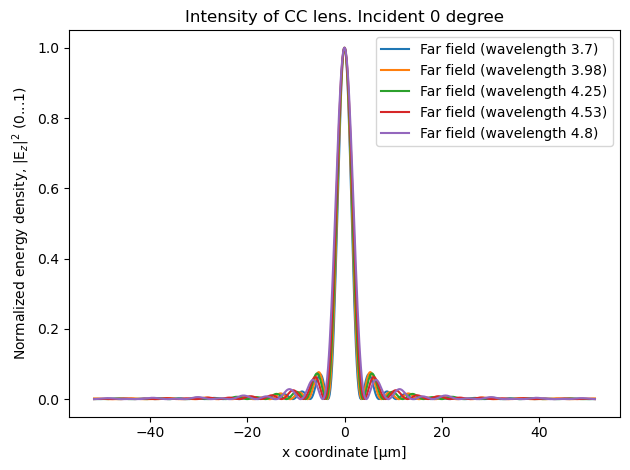

In [4]:
"""
Base
"""
# Для первичной инициализации params может принимать любые значения.
penalty_coef = 5.0
rt_tf = tf.calculate_radii_step(D=conf.aperture, orders=conf.orders)
rt_np = nf.calculate_radii_step(D=conf.aperture, orders=conf.orders)
d_rt_np, mid_rt_np = nf.get_drt_midrt(rt_np, conf.orders)
# инициализируем генератор
gen_resolution = nf.AdaptiveResolution(
    drt=d_rt_np,
    x_dim=conf.x_dim,
    h_dim= conf.h_dim,
)
# получаем список разрешений
resolutions_objs = gen_resolution.generate()
resolutions_tuples = [(r.w, r.h) for r in resolutions_objs]
angle = conf.angle_list[0]
symmetries = conf.symmetries

# Монитор
NearRegion = mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=conf.cell_Y))

# Источник моделируемой волны
# Если много волн
batch_sources = my_sources.BatchKvectorSource(
    frequencies=conf.inc_frequents_array,
    dfreq=conf.inc_df,
    y=conf.cell_Y,
    center=conf.source_center,
    angle=angle
)

sources = batch_sources.get_sources()

# IAiry_norm, sim = nf.get_IAiry_norm_simulation(NearRegion,save = False,symmetries = symmetries)
IAiry_norm, sim = nf.get_IAiry_norm_simulation_new(NearRegion, load = "Airy_simulation_5000.0_10.npy", save = True,symmetries = symmetries)

# Вариант 1. Собственный максимум
# Находим максимум по каждой колонке (axis=0 — по строкам, т.е. вдоль колонок)
max_per_column = IAiry_norm.max(axis=0)
# Нормируем каждую колонку на ее собственный максимум
IAiry_norm_scaled = IAiry_norm  * conf.reduction_coef_Airy / max_per_column
"""
# Вариант 2. Один максимум
# IAiry_norm_scaled = IAiry_norm / IAiry_norm.max()
"""
# Визуализация
nf.get_plot_intensity(
    conf.spot_ff,
    IAiry_norm_scaled,
    angle=conf.angle_list[0],
    wavelength_array=conf.inc_wavelength_array,
)

# # Проверка правильности волны Airy
# plt.figure(figsize=(1, 70))
# sim.plot2D(fields = mp.Ez, output_plane = mp.Volume(center=mp.Vector3(0, 0), size=mp.Vector3(conf.cell[0], conf.cell[1]))
# )

In [5]:
# Измерение интенсивности плоской волны
# Добавим подложку чтобы учитывать потери интенсивности в ней.
geometry = [mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, 0),
    center=mp.Vector3(conf.sub_center.x),
)]
IPlane_base = nf.get_Ibase_simulation(sources, geometry, conf.inc_frequents_array, symmetries = symmetries) *np.cos(np.radians(angle))
print("IPlane_base:", IPlane_base, "   dtype:", IPlane_base.dtype, "   ndim:", IPlane_base.ndim)
print("max_per_column:", max_per_column, "   dtype:", max_per_column.dtype, "   ndim:", max_per_column.ndim)

FloatProgress(value=0.0, description='0% done ', max=300.0)

IPlane_base: [30.52200137 24.28026083 19.41976188 14.86510347 11.19825651]    dtype: float64    ndim: 1
max_per_column: [0.01514865 0.01383685 0.01276421 0.01185769 0.01093777]    dtype: float64    ndim: 1


### 1.2 Инициализация оптимизатора

HTML(value='\n        \n        <style>\n            .live-panel { \n                border: 2px solid #4CAF50…

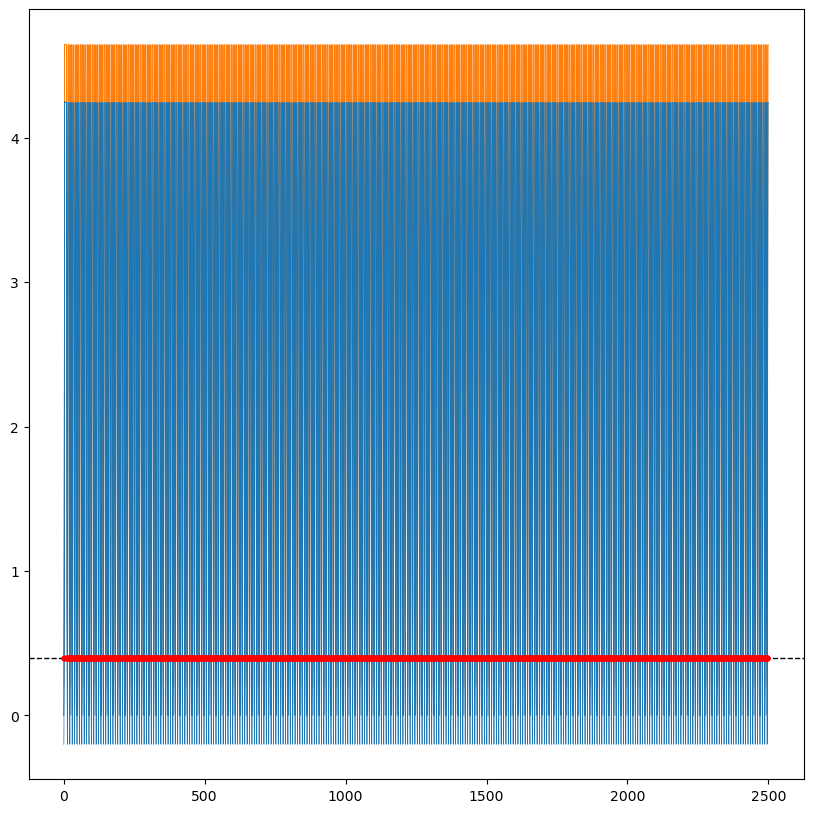

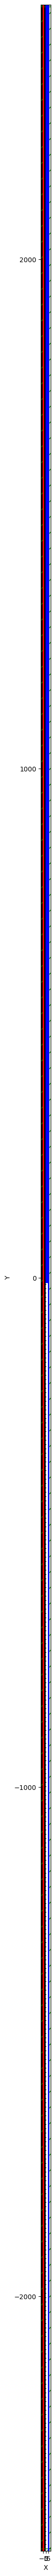

In [6]:
# Создадим листы областей дизайна, и точек замера интенсивностей
design_regions = []
focus_points_list = []
a_initial = 1.0
h_initial = 1.0
a_params = torch.full((conf.orders,), a_initial, dtype=torch.float64)
h_params = torch.full((conf.orders,), h_initial, dtype=torch.float64)
list_x0 = tf.material_grid_weight_2d(a_params, h_params, conf.at_hei, conf.orders, conf.stack, rt_tf, resolutions_tuples, Q = conf.Q, w = conf.w, LIMIT_SHAPE= conf.LIMIT_SHAPE, smooth = False, beta = 50.0, plot = True)
for order in range(conf.orders):
    weight_numpy = list_x0[order].detach().cpu().numpy() # тут вытаскиваем значения для первичной инициализации и для визуальной проверки
    res = resolutions_objs[order]
    material_grid = mp.MaterialGrid(
        mp.Vector3(x=res.h, y=res.w),
        mp.air,
        conf.at_material,
        weights=weight_numpy
    )
    design_regions.append(mpa.DesignRegion(
        material_grid,
        volume=mp.Volume(center=mp.Vector3(x = conf.at_hei/2, y=mid_rt_np[order]), size=mp.Vector3(x=conf.at_hei, y=d_rt_np[order]- 0.1)) # 0.1 небольшое смещение от края геометрии чтобы порядки не наехали друг на друга
    ))
    
    # a positive half 
    geometry.append(mp.Block(
        size=mp.Vector3(x=conf.at_hei, y=d_rt_np[order]),
        center=mp.Vector3(x=conf.at_hei/2, y=mid_rt_np[order]),
        material=material_grid,
    ))
    
    # a negative half
    geometry.append(mp.Block(
    size=mp.Vector3(x=conf.at_hei, y=d_rt_np[order]),
    center=mp.Vector3(x=conf.at_hei/2, y=-mid_rt_np[order]),
    material=material_grid,
    ))
   
sim = mp.Simulation(
    cell_size=conf.cell,
    boundary_layers=[mp.PML(thickness=conf.pml, direction=mp.ALL, side=mp.ALL)],
    geometry=geometry,
    sources=sources,
    default_material=mp.Medium(index=1.0),
    resolution=conf.min_resolution * conf.coef_resolution,
    symmetries = symmetries, # При наклонном падении света симметрию использовать нельзя
)

point1 = mp.Vector3(conf.f, nf.shift_y(angle), 0)
focus_points_list.append(point1)
FarFields = mpa.Near2FarFields(sim, [NearRegion], focus_points_list)
ob_list = [FarFields]

# Setup OptimizationProblem 
opt = mpa.OptimizationProblem(
    simulation=sim,
    objective_functions=[J],
    objective_arguments=ob_list, # ready 
    design_regions=design_regions, # ready 
    frequencies=conf.inc_frequents_array, # ready
    maximum_run_time= conf.maximum_run_time,
    until_steps=conf.maximum_run_time,
)
plt.figure(figsize=(1, 70))
opt.plot2D(True,
    output_plane = mp.Volume(center=mp.Vector3(0, 0), size=mp.Vector3(conf.cell[0], conf.cell[1]))
)
panel = my_gui.LiveInfoPanel()
panel.show()

### 2. Optimization loop

In [7]:
 # 1. Гиперпараметры
num_steps = 50          # число итераций оптимизации
lr=0.4                 # скорость обучения для Adam. Note: 0.1 - слишком мало (50 эпох), 0.25 - все еще мало (20-30 эпох), 0.5 - грубо (8-10 эпох). Вероятно есть зависимость от penalty_coef. Слишком медленное обучение. 0.5 - наиболее универсальный параметр.
beta = 2.0      # параметр сглаживания для get_weights

# 2. Инициализация параметров
p_min, p_max = 0.01, 30.0
h_min, h_max = 0.01, conf.at_hei

# 1) нормируем в [0,1] и инвертируем sigmoid
u_a0 = torch.log((a_params - p_min) / (p_max - a_params))
u_h0 = torch.log((h_params - h_min) / (h_max - h_params))
# 2) делаем параметры оптимизируемыми
u_a = torch.nn.Parameter(u_a0)
u_h = torch.nn.Parameter(u_h0)
# 3) заводим декодеры для обратного перехода в [p_min, p_max] и [h_min, h_max]
decoder_a = my_decoders.SigmoidDecoder(pmin=p_min, pmax=p_max)
decoder_h = my_decoders.SigmoidDecoder(pmin=h_min, pmax=h_max)

# 3. Оптимизатор
optimizer = torch.optim.Adam([u_a, u_h], lr=lr, betas=(0.95, 0.999)) # TODO: разобраться в значении betas (0.95, 0.999)

# 4.1 История
history = {
    'f0': [],
    'grad_norm': [],
    'a_params': [],
    'h_params': [],
    'beta': []
}

# 4.2 Параметры ранней остановки
patience = 3             # число шагов без существенного улучшения
threshold = 0.0001       # минимальный прирост f0, считающийся значимым
best_f0 = -float('inf')  # лучшее значение f0, с которого ведём отсчёт
wait = 0                 # счётчик шагов без улучшения

# 5. Цикл оптимизации
for step in range(1, num_steps + 1):
    optimizer.zero_grad()
    
    # 5.1. Декодируем параметры
    a_params = decoder_a(u_a)
    h_params = decoder_h(u_h)
    
    # 5.1. Получаем распределение epsilon
    # x — тензор размера (Nx_resolution, 1)
    x_list = tf.material_grid_weight_2d(a_params, h_params,  conf.at_hei, conf.orders, conf.stack, rt_tf, resolutions_tuples, Q = conf.Q, w = conf.w, LIMIT_SHAPE= conf.LIMIT_SHAPE, smooth = True, beta = beta, plot = False)

    # 5.2. Вычисляем функцию и её градиент через meep.adjoint.opt
    # opt ожидает список тензоров x, возвращает скаляр f0 и список градиентов [grad_x]   
    value = opt_torch(*x_list) # возвращает тензор-скаляр
    
    # # 5.9. Визуализируем
    # plt.figure(figsize=(1, 70))
    # sim.plot2D(
    #     output_plane = mp.Volume(center=mp.Vector3(0, 0), size=mp.Vector3(conf.cell[0], conf.cell[1])),
    #     label_geometry = False,
    #     plot_eps_flag = True,
    #     plot_sources_flag = False,
    #     plot_monitors_flag = False,
    #     plot_boundaries_flag = False,
    #     fields=mp.Ez,
    # )
    # plt.show()

    # 5.3. Переносим градиент на params через цепное правило:
    #      dx/dparams нам даёт get_weights.backward(), поэтому
    #      мы просто вызываем .backward() от -f0 (максимизируем f0)
    loss = -value
    loss.backward()
    
    # try:
    #     with torch.autograd.detect_anomaly():
    #         loss.backward()
    # except RuntimeError as e:
    #     print(f"Anomaly at step {step}: {e}")
    #     # здесь можно положить breakpoint
    #     raise
    

    # 5.4. Норма градиента для логирования
    grad_norm = 0.0
    for param in (u_a, u_h):
        grad_norm += param.grad.detach().norm().item()**2
    grad_norm = grad_norm**0.5
    
    # 5.5. Шаг оптимизатора
    optimizer.step()

    # 5.6. Увеличение beta для "закалки" бинарных масок
    beta = min(15.0, beta * 1.1)

    # 5.8. Сохраняем историю
    history['f0'].append(value.item())
    history['grad_norm'].append(grad_norm)
    history['a_params'].append(a_params.detach().cpu().clone())
    history['h_params'].append(h_params.detach().cpu().clone())
    history['beta'].append(beta)

    
    # 5.10. Логируем
    if step % 1 == 0 or step == 1:
        print(f"Step {step:3d} | f0 = {value.item()} | beta = {beta} ||grad|| = {grad_norm} || lr = {optimizer.param_groups[0]['lr']} || wait = {wait}")
    if (u_h.all() or u_a.all()) is None:
        print("Stopping optimization")
        break
    # --- ранняя остановка ---
    if value > best_f0 + threshold:
        best_f0 = value
        wait = 0
    else:
        wait += 1
    # --- ранняя остановка ---

    if wait >= patience:
        print(f"Early stopping at step {step}: "
              f"f0 hasn't improved by >{threshold} for {patience} steps")
        break

Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=300.0)

Starting adjoint run...


/home/eduser/pycharm/meta-neural-sci/meta-neural-sci_mvp/lib/adjoint/filter_source.py:187: RuntimeWarning: invalid value encountered in divide
  l2_err = np.sum(np.abs(H - H_hat.T) ** 2 / np.abs(H) ** 2)


FloatProgress(value=0.0, description='0% done ', max=300.0)

Calculating gradient...
Step   1 | f0 = 0.0013743448508137944 | beta = 2.2 ||grad|| = 0.00014421111180586103 || lr = 0.4 || wait = 0
Starting forward run...


... (56 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=300.0)

Starting adjoint run...


FloatProgress(value=0.0, description='0% done ', max=300.0)

Calculating gradient...
Step  16 | f0 = 0.22160104108141715 | beta = 9.189945972714444 ||grad|| = 0.0010676805933745336 || lr = 0.4 || wait = 2
Early stopping at step 16: f0 hasn't improved by >0.0001 for 3 steps


### 2.1 Output


Best f0 = 0.2405956119194631 at step 13


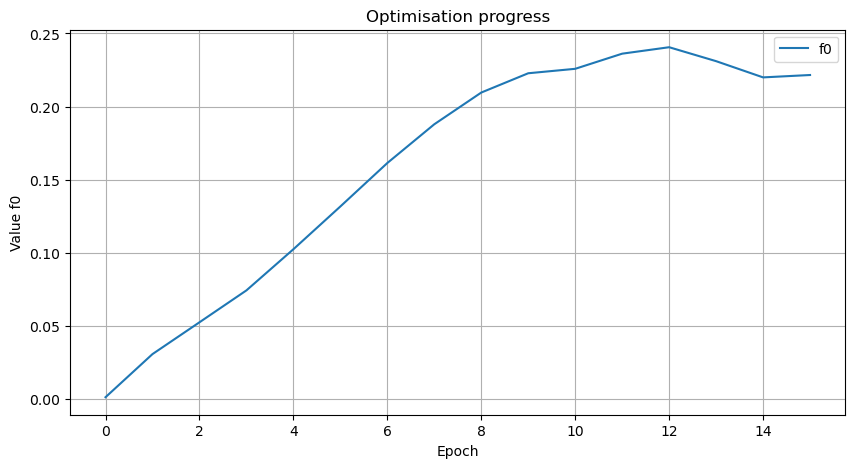

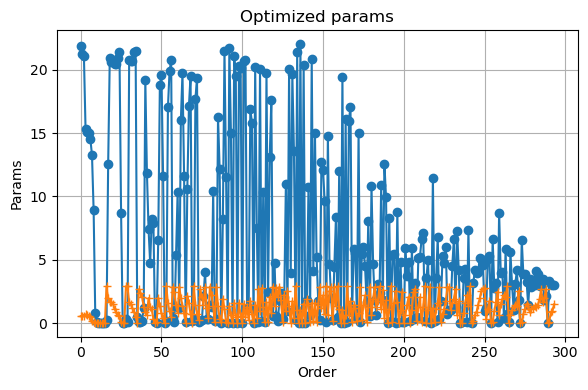

In [8]:
"""
VISUALIZATION
"""
# 6. По окончании params содержит оптимальное приближение
best_idx = max(range(len(history['f0'])), key=lambda i: history['f0'][i])
best_a_params = history['a_params'][best_idx]
best_h_params = history['h_params'][best_idx]
origin_a = history['a_params'][0]
origin_h = history['h_params'][0]
print(f"\nBest f0 = {history['f0'][best_idx]} at step {best_idx+1}")

# Построение графиков
plt.figure(figsize=(10, 5))
plt.plot(history['f0'], label='f0')
plt.xlabel('Epoch')
plt.ylabel('Value f0')
plt.title('Optimisation progress')
plt.legend()
plt.grid(True)
plt.show()

# 7. Строим график params
idx = torch.arange(conf.orders, dtype=torch.float32)
plt.figure(figsize=(6, 4))
plt.plot(idx.numpy(), best_a_params, marker='o')
plt.plot(idx.numpy(), best_h_params, marker='+')
plt.title('Optimized params')
plt.xlabel('Order')
plt.ylabel('Params')
plt.grid(True)
plt.tight_layout()
plt.show()

### 3. TEST

FloatProgress(value=0.0, description='0% done ', max=300.0)

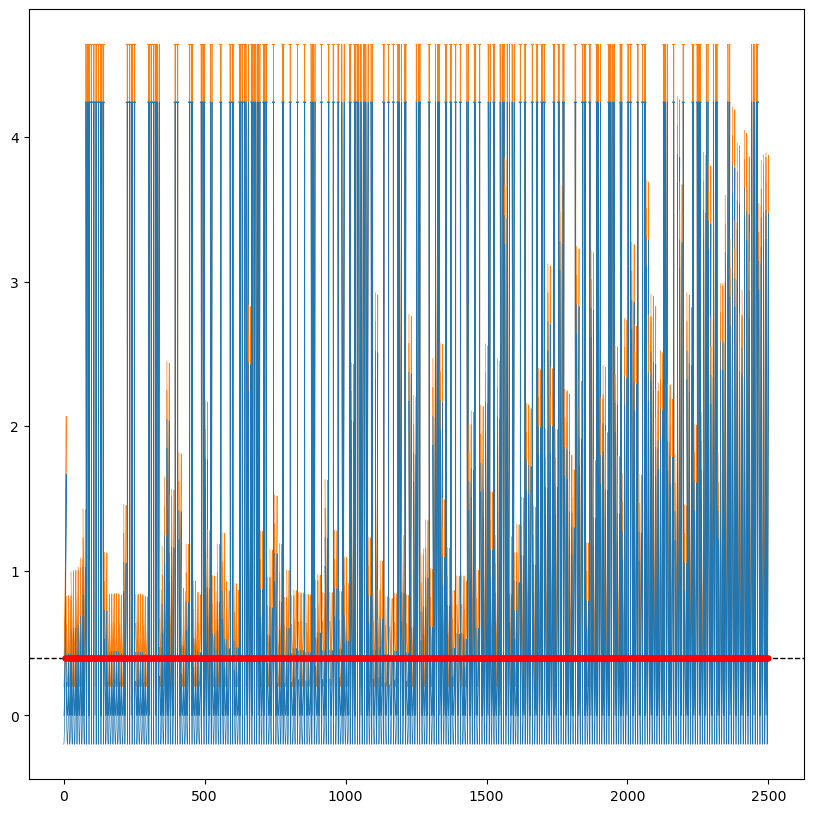

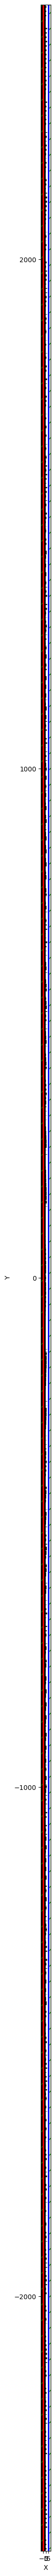

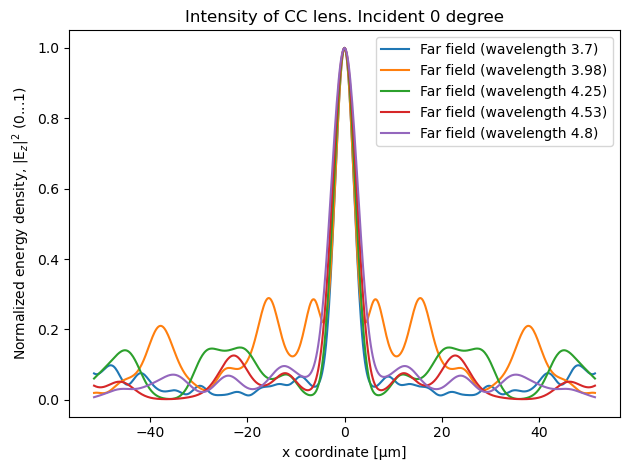

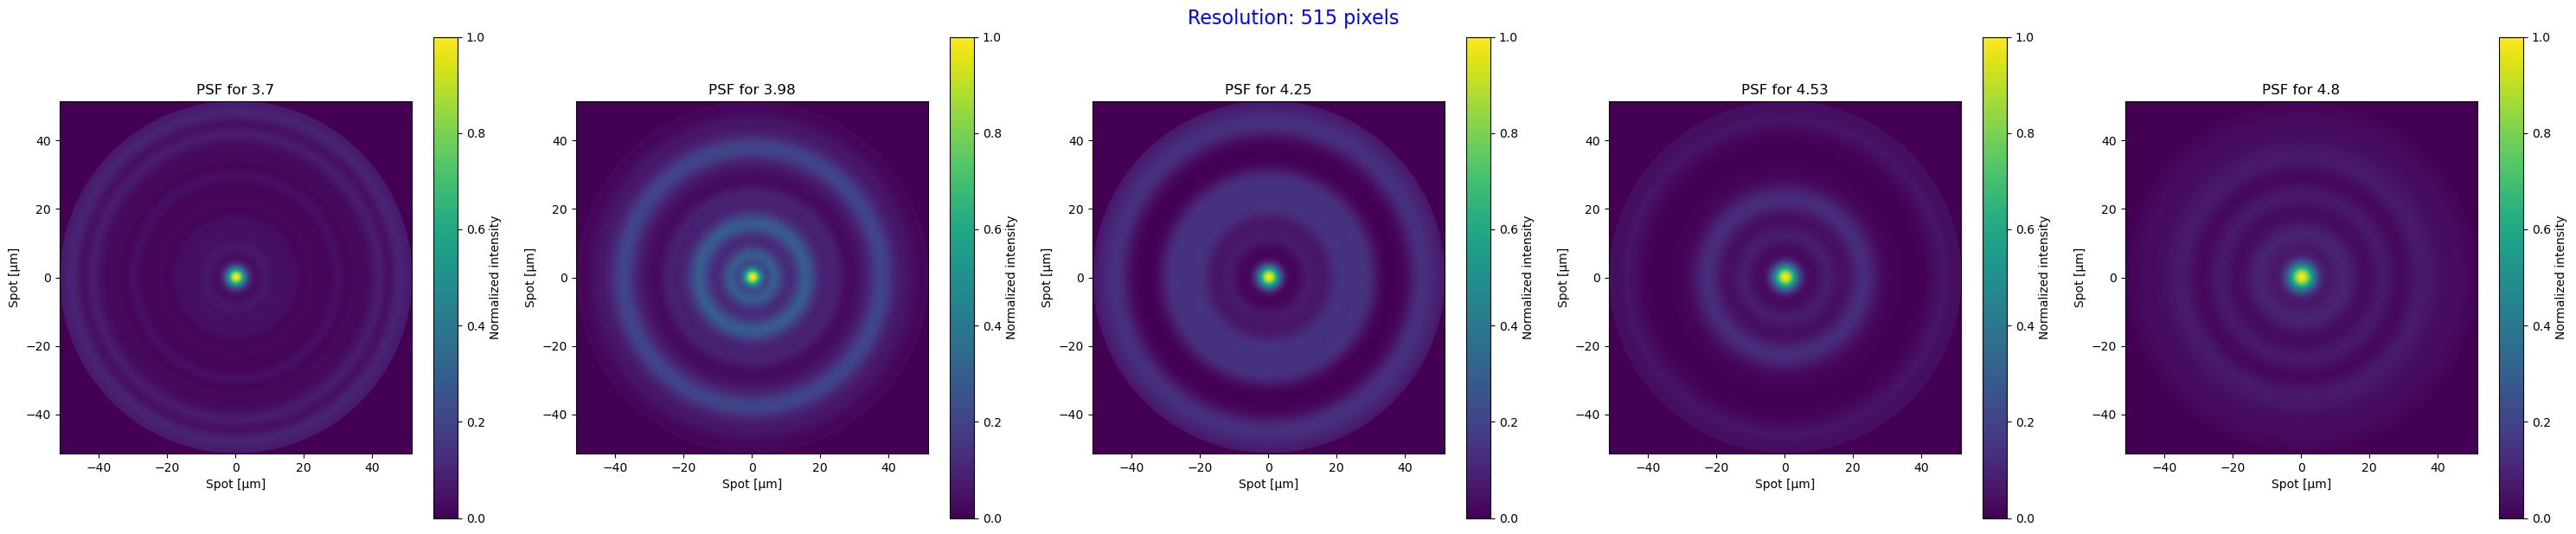

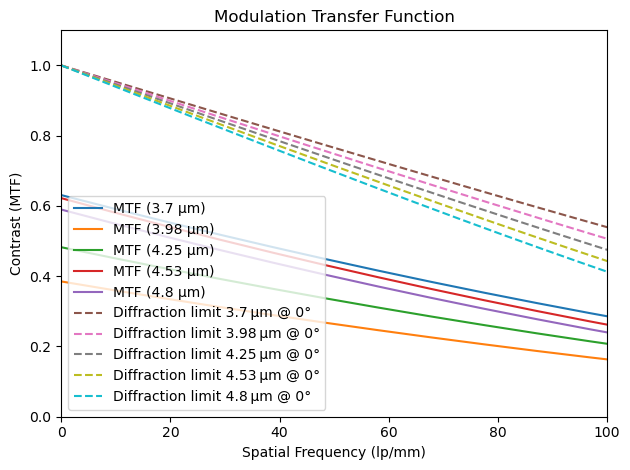

In [9]:
sim.reset_meep()
# angle = 60
# batch_sources = my_sources.BatchKvectorSource(
#     frequencies=conf.inc_frequents_array,
#     dfreq=conf.inc_df,
#     y=conf.cell_Y,
#     center=conf.source_center,
#     angle=angle
# )
# sources = batch_sources.get_sources()
NearRegion = mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=conf.cell_Y))
# best_a_params = torch.load("d5_best_a_5_waves_2_params_0deg_average.pt", weights_only=True)
# best_h_params = torch.load("d5_best_h_5_waves_2_params_0deg_average.pt", weights_only=True)
x_test = tf.material_grid_weight_2d(best_a_params, best_h_params, conf.at_hei, conf.orders, conf.stack, rt_tf, resolutions_tuples, Q = conf.Q, w = conf.w, LIMIT_SHAPE= conf.LIMIT_SHAPE, smooth = False, beta = 50, plot = True)
for order in range(conf.orders):
    weight_numpy = x_test[order].detach().cpu().numpy() # тут вытаскиваем значения для первичной инициализации и для визуальной проверки
    res = resolutions_objs[order]
    material_grid = mp.MaterialGrid(
        mp.Vector3(x=res.h, y=res.w),
        mp.air,
        conf.at_material,
        weights=weight_numpy
    )
    design_regions.append(mpa.DesignRegion(
        material_grid,
        volume=mp.Volume(center=mp.Vector3(x = conf.at_hei/2, y=mid_rt_np[order]), size=mp.Vector3(x=conf.at_hei, y=d_rt_np[order]- 0.5)) # 0.1 небольшое смещение от края геометрии чтобы порядки не наехали друг на друга
    ))
    # a positive half 
    geometry.append(mp.Block(
        size=mp.Vector3(x=conf.at_hei, y=d_rt_np[order]),
        center=mp.Vector3(x=conf.at_hei/2, y=mid_rt_np[order]),
        material=material_grid,
    ))
    
    # a negative half
    geometry.append(mp.Block(
    size=mp.Vector3(x=conf.at_hei, y=d_rt_np[order]),
    center=mp.Vector3(x=conf.at_hei/2, y=-mid_rt_np[order]),
    material=material_grid,
    ))

sim = mp.Simulation(
    cell_size=conf.cell,
    boundary_layers= [mp.PML(thickness=conf.pml, direction=mp.X , side=mp.ALL)],
    geometry=geometry,
    sources=sources,
    default_material=mp.Medium(index=1.0),
    resolution=conf.min_resolution * conf.coef_resolution,
    symmetries = symmetries,
)

# Adding a near2far area
near2far_region = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    conf.inc_df,      # ширина спектра
    conf.inc_nfreq, # дискретность частот
    NearRegion,
)

near2far_regions = []
for i in range(conf.inc_nfreq):
    near2far_region = sim.add_near2far(
        conf.inc_frequents_array[i],  # центральная частота
        conf.inc_df,    # ширина спектра
        1, # дискретность частот
        NearRegion,
    )
    near2far_regions.append(near2far_region)

plt.figure(figsize=(1, 70))
sim.plot2D(output_plane = mp.Volume(center=mp.Vector3(0, 0), size=mp.Vector3(conf.cell[0], conf.cell[1]))
)
sim.run(until=conf.maximum_run_time)
IOptimized = nf.get_I(sim, near2far_regions,conf.ff_res, mp.Vector3(0, conf.spot_ff, 0), angle = angle, f = conf.f)
IOptimized_norm = IOptimized/IPlane_base
# Вариант 1. Индивидуальный максимум
max_per_column_optimized = IOptimized_norm.max(axis=0)
IOptimized_norm_scaledToAiry = IOptimized_norm / max_per_column_optimized
"""
# Вариант 2. Один максимум
IOptimized_norm_scaledToAiry = IOptimized_norm / IAiry_norm.max()
"""
nf.get_plot_intensity(conf.spot_ff, IOptimized_norm_scaledToAiry, angle = angle, wavelength_array=conf.inc_wavelength_array)
nf.plot_psf(conf.inc_nfreq, conf.spot_ff, IOptimized_norm_scaledToAiry, angle = angle)
nf.plot_mtf(conf.spot_ff, IOptimized_norm_scaledToAiry, max_view = 100, angle = angle, dif_lim= True, smooth= True)

### Utilities

In [8]:
# To comparison with Airy. Better not use with several wavelengths 
# list_I = [IAiry_norm_scaled, IOptimized_norm_scaledToAiry]
# nf.get_plot_intensity_multiply(conf.spot_ff, list_I, angle = conf.angle_list)
# nf.generate_lens_gds(np_a_params,  conf.orders, rt_np, Q = conf.Q, w = conf.w)
help_functions.save_params(params = best_a_params, name = "d5_best_a_5_waves_2_params_30deg_average")
help_functions.save_params(params = best_h_params, name = "d5_best_h_5_waves_2_params_30deg_average")

Saved NumPy array to ./d5_best_a_5_waves_2_params_30deg_average.npy
Saved Torch tensor to ./d5_best_a_5_waves_2_params_30deg_average.pt
Saved NumPy array to ./d5_best_h_5_waves_2_params_30deg_average.npy
Saved Torch tensor to ./d5_best_h_5_waves_2_params_30deg_average.pt
